In [1]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
# load the dataset into a dataframe
df = pd.read_csv("powerconsumption.csv")

In [3]:
# view the first 5 rows
df.head()

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


In [4]:
# check the dataset's dimensions
df.shape

(52416, 9)

In [5]:
# check the column names
df.columns

Index(['Datetime', 'Temperature', 'Humidity', 'WindSpeed',
       'GeneralDiffuseFlows', 'DiffuseFlows', 'PowerConsumption_Zone1',
       'PowerConsumption_Zone2', 'PowerConsumption_Zone3'],
      dtype='object')

In [6]:
# check the data types and whether any column have missing entries
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Datetime                52416 non-null  object 
 1   Temperature             52416 non-null  float64
 2   Humidity                52416 non-null  float64
 3   WindSpeed               52416 non-null  float64
 4   GeneralDiffuseFlows     52416 non-null  float64
 5   DiffuseFlows            52416 non-null  float64
 6   PowerConsumption_Zone1  52416 non-null  float64
 7   PowerConsumption_Zone2  52416 non-null  float64
 8   PowerConsumption_Zone3  52416 non-null  float64
dtypes: float64(8), object(1)
memory usage: 3.6+ MB


In [7]:
# check for duplicate records
df.duplicated().sum()

0

In [8]:
# convert the Datetime column from object to actual Date/Time
df['Datetime'] = pd.to_datetime(df['Datetime'])

In [9]:
# check the date range covered by the dataset
df['Datetime'].min(), df['Datetime'].max()

(Timestamp('2017-01-01 00:00:00'), Timestamp('2017-12-30 23:50:00'))

In [10]:
# check whether readings were recorded consistently every 10 minutes
df['Datetime'].diff().value_counts()

Datetime
0 days 00:10:00    52415
Name: count, dtype: int64

In [11]:
# examine the numerical data
df.describe()

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
count,52416,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000
mean,2017-07-01 23:55:00,18.810024,68.259518,1.959489,182.696614,75.028022,32344.970564,21042.509082,17835.406218
min,2017-01-01 00:00:00,3.247000,11.340000,0.050000,0.004000,0.011000,13895.696200,8560.081466,5935.174070
25%,2017-04-01 23:57:30,14.410000,58.310000,0.078000,0.062000,0.122000,26310.668692,16980.766032,13129.326630
50%,2017-07-01 23:55:00,18.780000,69.860000,0.086000,5.035500,4.456000,32265.920340,20823.168405,16415.117470
75%,2017-09-30 23:52:30,22.890000,81.400000,4.915000,319.600000,101.000000,37309.018185,24713.717520,21624.100420
max,2017-12-30 23:50:00,40.010000,94.800000,6.483000,1163.000000,936.000000,52204.395120,37408.860760,47598.326360
std,NaN,5.815476,15.551177,2.348862,264.400960,124.210949,7130.562564,5201.465892,6622.165099


In [12]:
# check whether any numerical values are negative
df.select_dtypes(include='number').lt(0).sum()

Temperature               0
Humidity                  0
WindSpeed                 0
GeneralDiffuseFlows       0
DiffuseFlows              0
PowerConsumption_Zone1    0
PowerConsumption_Zone2    0
PowerConsumption_Zone3    0
dtype: int64

In [13]:
# check for missing values again
df.isnull().sum()

Datetime                  0
Temperature               0
Humidity                  0
WindSpeed                 0
GeneralDiffuseFlows       0
DiffuseFlows              0
PowerConsumption_Zone1    0
PowerConsumption_Zone2    0
PowerConsumption_Zone3    0
dtype: int64

In [14]:
# check for duplicated timestamps
df['Datetime'].duplicated().sum()

0

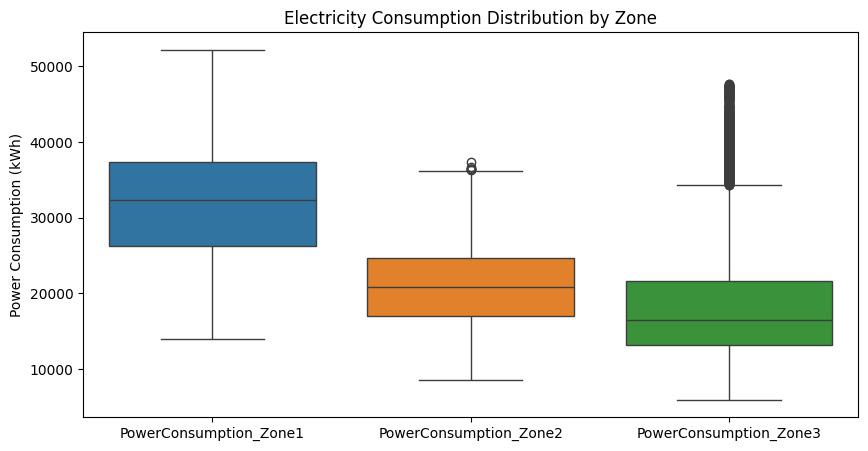

In [15]:
# investigating unusual or extreme electricity consumption values
plt.figure(figsize=(10, 5))

sns.boxplot(data=df[['PowerConsumption_Zone1',
                     'PowerConsumption_Zone2',
                     'PowerConsumption_Zone3']])

plt.title('Electricity Consumption Distribution by Zone')
plt.ylabel('Power Consumption (kWh)')
plt.show()

In [16]:
# find the extreme readings
df[['PowerConsumption_Zone1',
    'PowerConsumption_Zone2',
    'PowerConsumption_Zone3']].max()

PowerConsumption_Zone1    52204.39512
PowerConsumption_Zone2    37408.86076
PowerConsumption_Zone3    47598.32636
dtype: float64

In [17]:
# Check when these highest readings occurred. This will help us to know the date and time of each zone's highest reading.
consumption_columns = [
    'PowerConsumption_Zone1',
    'PowerConsumption_Zone2',
    'PowerConsumption_Zone3'
]

for col in consumption_columns:
    print(col)
    print(df.loc[df[col].idxmax(), ['Datetime', col]])
    print()

PowerConsumption_Zone1
Datetime                  2017-08-07 20:20:00
PowerConsumption_Zone1            52204.39512
Name: 31514, dtype: object

PowerConsumption_Zone2
Datetime                  2017-07-24 19:40:00
PowerConsumption_Zone2            37408.86076
Name: 29494, dtype: object

PowerConsumption_Zone3
Datetime                  2017-07-24 20:10:00
PowerConsumption_Zone3            47598.32636
Name: 29497, dtype: object



In [18]:
# Are these readings actually outliers?
Q1 = df['PowerConsumption_Zone1'].quantile(0.25)
Q3 = df['PowerConsumption_Zone1'].quantile(0.75)

IQR = Q3 - Q1

upper_limit = Q3 + (1.5 * IQR)
lower_limit = Q1 - (1.5 * IQR)

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Lower limit: 9813.144453749996
Upper limit: 53806.542423750005


In [19]:
# To confirm whether Zone 1 has any outliers
outliers_zone1 = df[
    (df['PowerConsumption_Zone1'] < lower_limit) |
    (df['PowerConsumption_Zone1'] > upper_limit)
]

print("Number of outliers:", len(outliers_zone1))

Number of outliers: 0


In [20]:
# for zone 2 and zone 3
for col in ['PowerConsumption_Zone2', 'PowerConsumption_Zone3']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - (1.5 * IQR)
    upper_limit = Q3 + (1.5 * IQR)

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print(col)
    print("Lower limit:", lower_limit)
    print("Upper limit:", upper_limit)
    print("Number of outliers:", len(outliers))
    print()

PowerConsumption_Zone2
Lower limit: 5381.338801250002
Upper limit: 36313.144751249994
Number of outliers: 7

PowerConsumption_Zone3
Lower limit: 387.16594500000065
Upper limit: 34366.261105
Number of outliers: 1191



In [21]:
# find out whether they are high or low outliers
for col in ['PowerConsumption_Zone2', 'PowerConsumption_Zone3']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - (1.5 * IQR)
    upper_limit = Q3 + (1.5 * IQR)

    low_outliers = (df[col] < lower_limit).sum()
    high_outliers = (df[col] > upper_limit).sum()

    print(col)
    print("Low outliers:", low_outliers)
    print("High outliers:", high_outliers)
    print()

PowerConsumption_Zone2
Low outliers: 0
High outliers: 7

PowerConsumption_Zone3
Low outliers: 0
High outliers: 1191



In [22]:
# creating time-based columns. For Year
df['Year'] = df['Datetime'].dt.year

In [23]:
# Month
df['Month'] = df['Datetime'].dt.month

In [24]:
# Day
df['Day'] = df['Datetime'].dt.day

In [25]:
# Hour
df['Hour'] = df['Datetime'].dt.hour

In [26]:
# Day of the week
df['Day_of_Week'] = df['Datetime'].dt.day_name()

In [27]:
# Date
df['Date'] = df['Datetime'].dt.date

In [28]:
df[['Datetime', 'Year', 'Month', 'Day', 'Hour', 'Day_of_Week', 'Date']].head()

,Datetime,Year,Month,Day,Hour,Day_of_Week,Date
0,2017-01-01 00:00:00,2017,1,1,0,Sunday,2017-01-01
1,2017-01-01 00:10:00,2017,1,1,0,Sunday,2017-01-01
2,2017-01-01 00:20:00,2017,1,1,0,Sunday,2017-01-01
3,2017-01-01 00:30:00,2017,1,1,0,Sunday,2017-01-01
4,2017-01-01 00:40:00,2017,1,1,0,Sunday,2017-01-01


In [29]:
# average consumption for each zone across all recorded readings
zone_columns = [
    'PowerConsumption_Zone1',
    'PowerConsumption_Zone2',
    'PowerConsumption_Zone3'
]

df[zone_columns].mean()

PowerConsumption_Zone1    32344.970564
PowerConsumption_Zone2    21042.509082
PowerConsumption_Zone3    17835.406218
dtype: float64

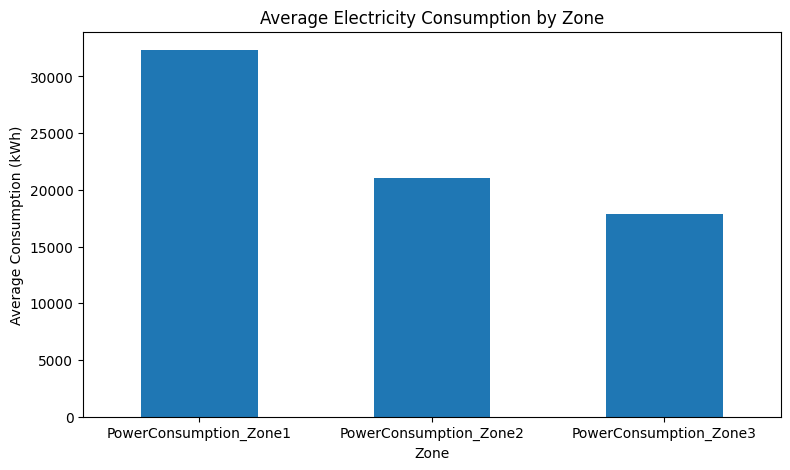

In [30]:
# average consumption visualization
average_consumption = df[zone_columns].mean()

average_consumption.plot(
    kind='bar',
    figsize=(9, 5),
    title='Average Electricity Consumption by Zone',
    ylabel='Average Consumption (kWh)',
    xlabel='Zone'
)

plt.xticks(rotation=0)
plt.show()

In [31]:
# highest consumption reading for each zone
for col in zone_columns:
    highest = df[col].idxmax()
    print(col)
    print(df.loc[highest, ['Datetime', col]])
    print()

PowerConsumption_Zone1
Datetime                  2017-08-07 20:20:00
PowerConsumption_Zone1            52204.39512
Name: 31514, dtype: object

PowerConsumption_Zone2
Datetime                  2017-07-24 19:40:00
PowerConsumption_Zone2            37408.86076
Name: 29494, dtype: object

PowerConsumption_Zone3
Datetime                  2017-07-24 20:10:00
PowerConsumption_Zone3            47598.32636
Name: 29497, dtype: object



In [32]:
# lowest consumption readings
for col in zone_columns:
    lowest = df[col].idxmin()
    print(col)
    print(df.loc[lowest, ['Datetime', col]])
    print()

PowerConsumption_Zone1
Datetime                  2017-01-15 07:30:00
PowerConsumption_Zone1             13895.6962
Name: 2061, dtype: object

PowerConsumption_Zone2
Datetime                  2017-04-02 06:10:00
PowerConsumption_Zone2            8560.081466
Name: 13141, dtype: object

PowerConsumption_Zone3
Datetime                  2017-12-11 07:00:00
PowerConsumption_Zone3             5935.17407
Name: 49578, dtype: object



In [33]:
# hourly consumption patterns
hourly_consumption = df.groupby('Hour')[zone_columns].mean()

hourly_consumption

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Hour,,,
0,30217.235372,19692.073550,18657.222811
1,27565.533030,17765.078949,16970.804696
2,26292.688917,16730.156092,15981.096176
3,25338.122851,16052.585288,15238.605002
4,24633.576717,15624.081077,14671.039080
5,23437.577276,14974.907723,13226.380008
6,23203.597394,14934.698604,12051.599729
7,24038.353352,15719.115067,11667.864458
8,26583.262396,17529.678454,12793.786057


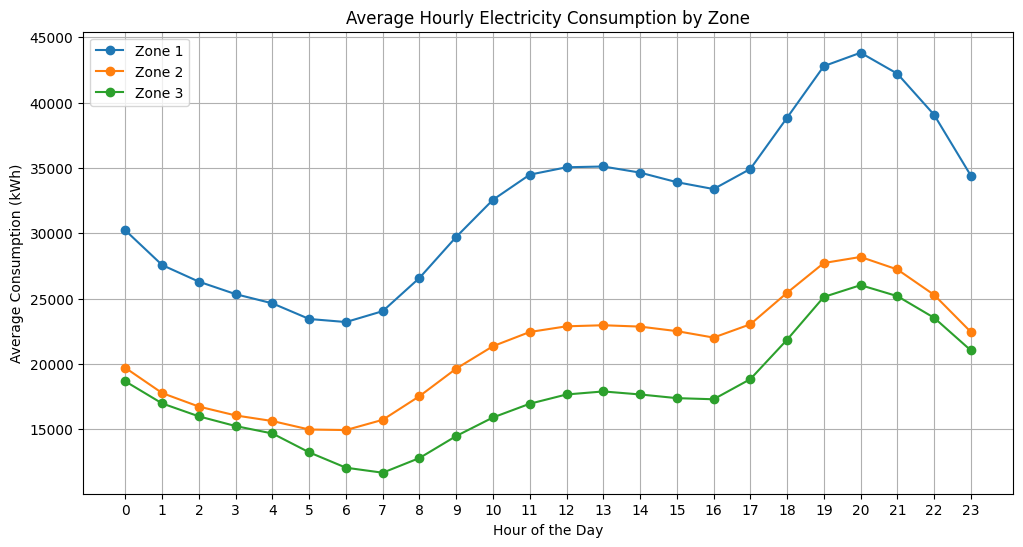

In [34]:
# hourly consumption patterns visualization
hourly_consumption.plot(
    kind='line',
    figsize=(12, 6),
    marker='o',
    title='Average Hourly Electricity Consumption by Zone'
)

plt.xlabel('Hour of the Day')
plt.ylabel('Average Consumption (kWh)')
plt.xticks(range(24))
plt.grid(True)
plt.legend(['Zone 1', 'Zone 2', 'Zone 3'])
plt.show()

In [35]:
# daily consumption patterns
daily_consumption = df.groupby('Day_of_Week')[zone_columns].mean()

daily_consumption

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Day_of_Week,,,
Friday,32338.995905,21461.038263,17545.971382
Monday,32615.410633,21280.065085,17809.081562
Saturday,32253.034345,20585.955724,18011.187469
Sunday,30780.079481,18979.377434,17954.827782
Thursday,32842.484416,21845.164469,17843.692103
Tuesday,32713.030148,21518.599887,17831.688173
Wednesday,32871.759018,21627.362715,17851.395059


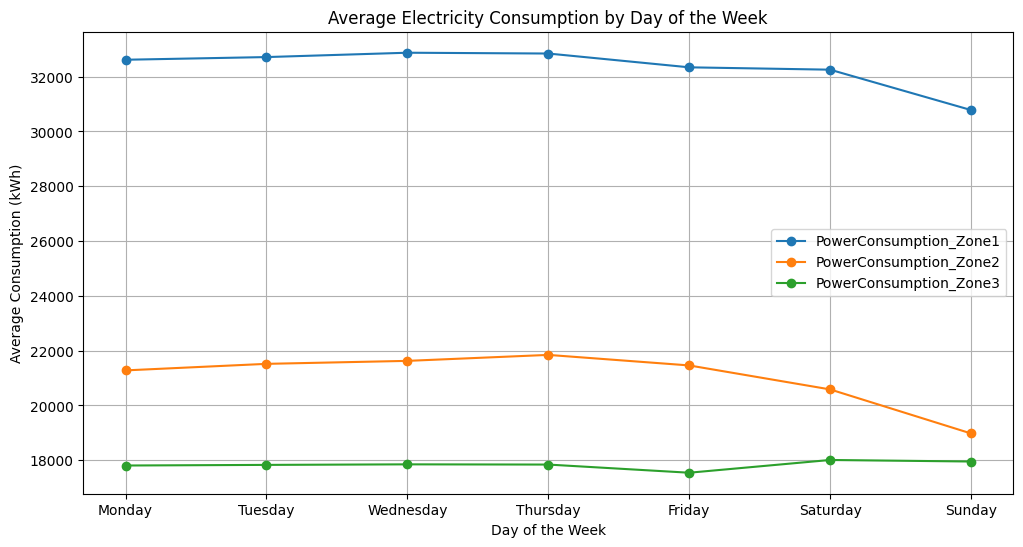

In [36]:
# weekly consumption patterns visualization
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

daily_consumption = daily_consumption.reindex(day_order)

daily_consumption.plot(
    kind='line',
    figsize=(12, 6),
    marker='o',
    title='Average Electricity Consumption by Day of the Week'
)

plt.xlabel('Day of the Week')
plt.ylabel('Average Consumption (kWh)')
plt.grid(True)
plt.show()

In [37]:
# monthly consumption patterns
monthly_consumption = df.groupby('Month')[zone_columns].mean()
monthly_consumption

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Month,,,
1,31032.493535,19394.444717,17746.095349
2,30985.753632,18787.793096,17335.002154
3,31155.165408,18457.937484,16947.686004
4,31169.768210,17633.966395,18593.167677
5,32396.009166,19977.287859,17621.100953
6,34605.540839,20670.928621,20430.941538
7,35831.553603,24147.886893,28194.111216
8,36435.189574,24656.216575,24648.894732
9,33396.681416,20180.432259,14922.798774


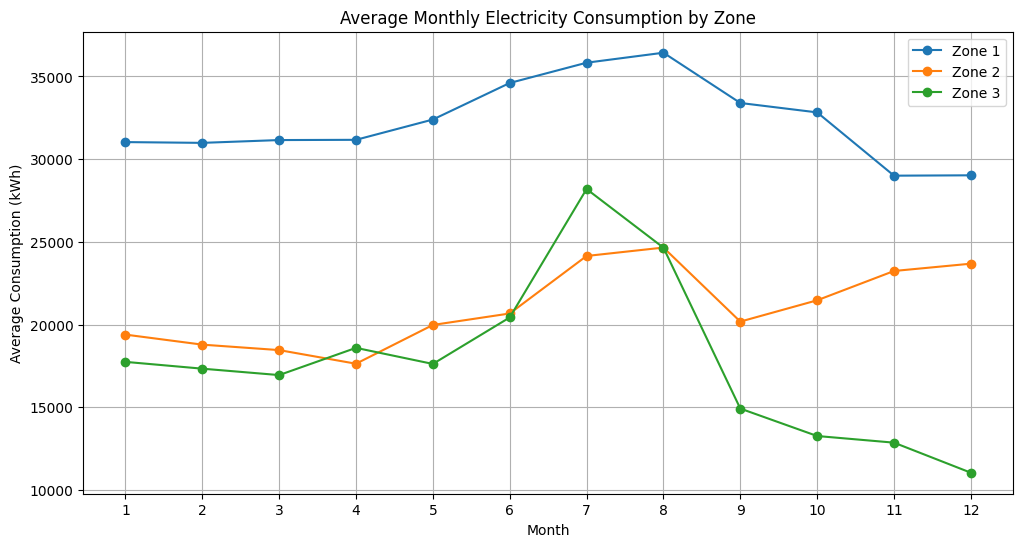

In [38]:
# Monthly consumption patterns visualization
monthly_consumption.plot(
    kind='line',
    figsize=(12, 6),
    marker='o',
    title='Average Monthly Electricity Consumption by Zone'
)

plt.xlabel('Month')
plt.ylabel('Average Consumption (kWh)')
plt.xticks(range(1, 13))
plt.grid(True)
plt.legend(['Zone 1', 'Zone 2', 'Zone 3'])
plt.show()

In [39]:
# comparing weekday and weekend consumption
df['Day_Type'] = df['Day_of_Week'].apply(
    lambda day: 'Weekend' if day in ['Saturday', 'Sunday'] else 'Weekday'
)

weekend_comparison = df.groupby('Day_Type')[zone_columns].mean()

weekend_comparison

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Day_Type,,,
Weekday,32676.336024,21546.446084,17776.365656
Weekend,31516.556913,19782.666579,17983.007625


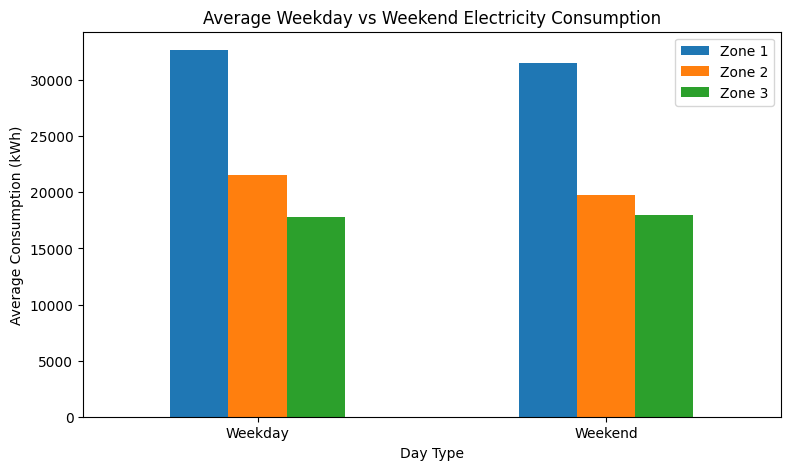

In [40]:
# visualization
weekend_comparison.plot(
    kind='bar',
    figsize=(9, 5),
    title='Average Weekday vs Weekend Electricity Consumption'
)

plt.xlabel('Day Type')
plt.ylabel('Average Consumption (kWh)')
plt.xticks(rotation=0)
plt.legend(['Zone 1', 'Zone 2', 'Zone 3'])
plt.show()

In [41]:
# difference between the three zones
zone_averages = df[zone_columns].mean()

zone_averages

PowerConsumption_Zone1    32344.970564
PowerConsumption_Zone2    21042.509082
PowerConsumption_Zone3    17835.406218
dtype: float64

In [42]:
# percentage difference
zone_comparison = pd.DataFrame({
    'Average Consumption': zone_averages
})

zone_comparison['Difference from Zone 1 (%)'] = (
    (zone_averages - zone_averages['PowerConsumption_Zone1'])
    / zone_averages['PowerConsumption_Zone1']
) * 100

zone_comparison

,Average Consumption,Difference from Zone 1 (%)
PowerConsumption_Zone1,32344.970564,0.000000
PowerConsumption_Zone2,21042.509082,-34.943490
PowerConsumption_Zone3,17835.406218,-44.858796


In [43]:
# correlation between temperature and electricity consumption in all three zones
temperature_correlation = df[
    ['Temperature'] + zone_columns
].corr()

temperature_correlation

,Temperature,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Temperature,1.000000,0.440221,0.382428,0.489527
PowerConsumption_Zone1,0.440221,1.000000,0.834519,0.750733
PowerConsumption_Zone2,0.382428,0.834519,1.000000,0.570932
PowerConsumption_Zone3,0.489527,0.750733,0.570932,1.000000


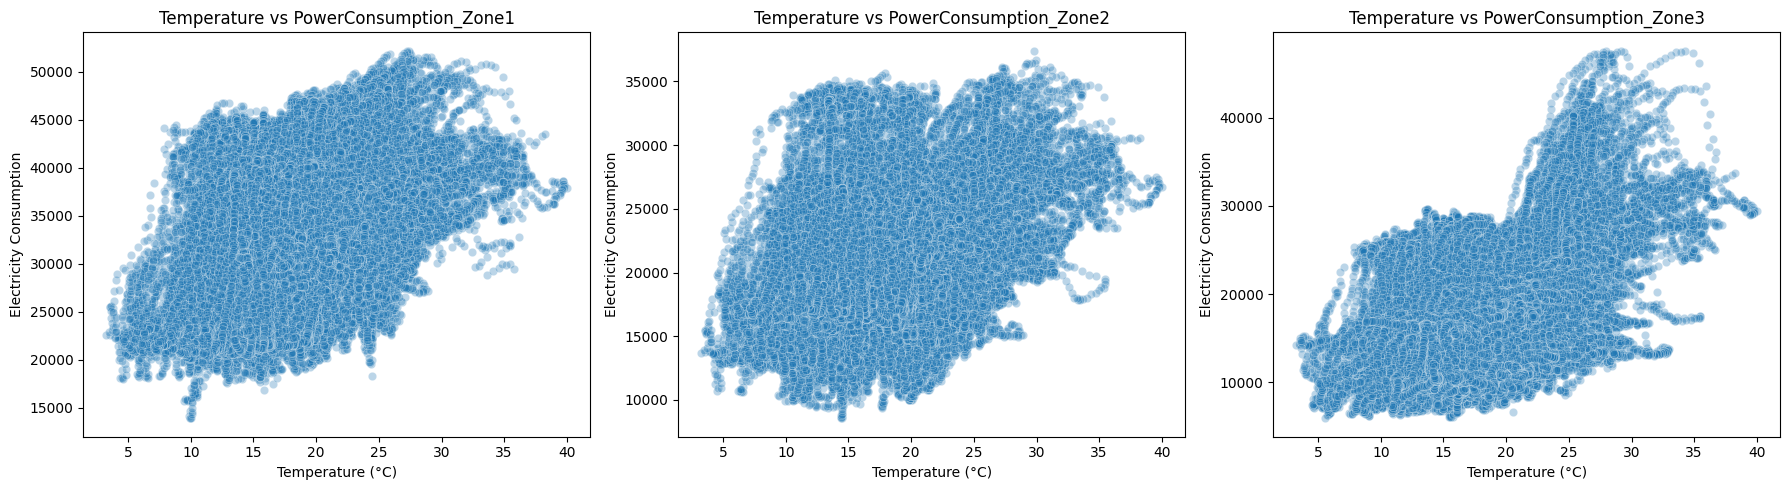

In [44]:
# visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(zone_columns):
    sns.scatterplot(
        data=df,
        x='Temperature',
        y=col,
        alpha=0.3,
        ax=axes[i]
    )
    axes[i].set_title(f'Temperature vs {col}')
    axes[i].set_xlabel('Temperature (°C)')
    axes[i].set_ylabel('Electricity Consumption')

plt.tight_layout()
plt.show()

In [45]:
# humidity and elecrticity consumption
humidity_correlation = df[
    ['Humidity'] + zone_columns
].corr()

humidity_correlation

,Humidity,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Humidity,1.000000,-0.287421,-0.294961,-0.233022
PowerConsumption_Zone1,-0.287421,1.000000,0.834519,0.750733
PowerConsumption_Zone2,-0.294961,0.834519,1.000000,0.570932
PowerConsumption_Zone3,-0.233022,0.750733,0.570932,1.000000


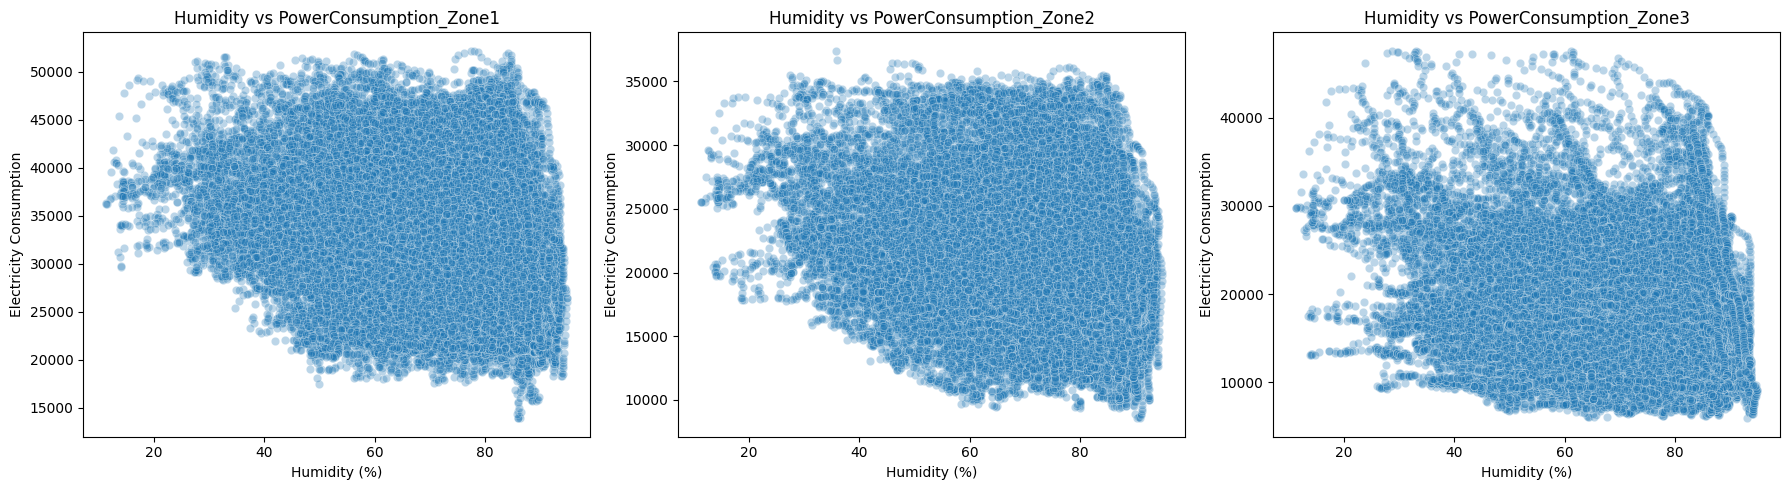

In [46]:
# visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(zone_columns):
    sns.scatterplot(
        data=df,
        x='Humidity',
        y=col,
        alpha=0.3,
        ax=axes[i]
    )
    axes[i].set_title(f'Humidity vs {col}')
    axes[i].set_xlabel('Humidity (%)')
    axes[i].set_ylabel('Electricity Consumption')

plt.tight_layout()
plt.show()

In [47]:
# wind speed and electricity consumption
wind_correlation = df[
    ['WindSpeed'] + zone_columns
].corr()

wind_correlation

,WindSpeed,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
WindSpeed,1.000000,0.167444,0.146413,0.278641
PowerConsumption_Zone1,0.167444,1.000000,0.834519,0.750733
PowerConsumption_Zone2,0.146413,0.834519,1.000000,0.570932
PowerConsumption_Zone3,0.278641,0.750733,0.570932,1.000000


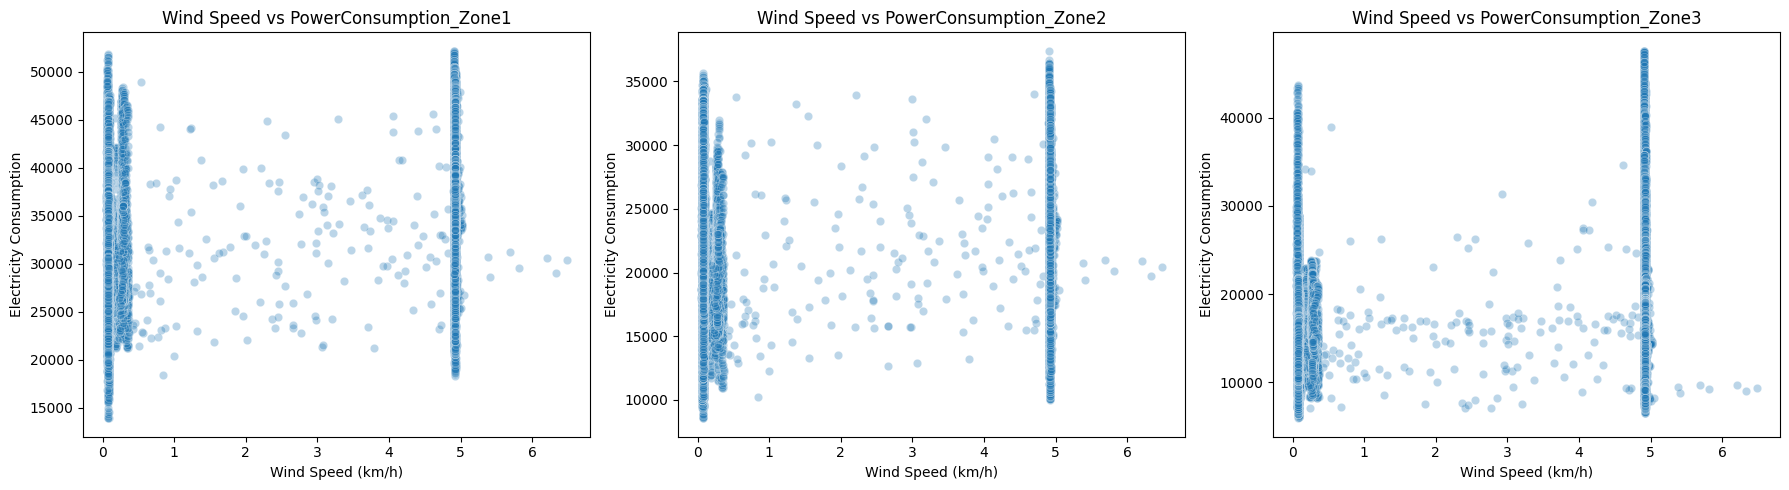

In [48]:
# visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(zone_columns):
    sns.scatterplot(
        data=df,
        x='WindSpeed',
        y=col,
        alpha=0.3,
        ax=axes[i]
    )
    axes[i].set_title(f'Wind Speed vs {col}')
    axes[i].set_xlabel('Wind Speed (km/h)')
    axes[i].set_ylabel('Electricity Consumption')

plt.tight_layout()
plt.show()

In [49]:
# investigate the unusual wind-speed readings
df['WindSpeed'].value_counts().head(15)

WindSpeed
0.082    2291
0.083    1979
0.084    1831
0.081    1804
0.085    1513
0.080    1502
0.073    1485
4.919    1430
4.916    1375
0.072    1369
0.071    1358
4.918    1353
4.917    1347
4.920    1342
0.070    1308
Name: count, dtype: int64

In [50]:
# check the distribution of wind speed
df['WindSpeed'].describe()

count    52416.000000
mean         1.959489
std          2.348862
min          0.050000
25%          0.078000
50%          0.086000
75%          4.915000
max          6.483000
Name: WindSpeed, dtype: float64

In [51]:
# comparison
environmental_correlation = df[
    ['Temperature', 'Humidity', 'WindSpeed'] + zone_columns
].corr()

environmental_correlation.loc[
    ['Temperature', 'Humidity', 'WindSpeed'],
    zone_columns
]

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Temperature,0.440221,0.382428,0.489527
Humidity,-0.287421,-0.294961,-0.233022
WindSpeed,0.167444,0.146413,0.278641


In [52]:
# electricity consumption trend over time
daily_trend = df.groupby('Date')[zone_columns].mean()

daily_trend.head()

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Date,,,
2017-01-01,28465.232067,17737.791287,17868.795181
2017-01-02,28869.493671,19557.725431,17820.763053
2017-01-03,30562.447257,20057.269504,17620.803213
2017-01-04,30689.831224,20102.077001,17673.694779
2017-01-05,30802.911393,20033.941237,17664.176707


In [53]:
# prepare the Date column for Plotly
daily_trend = daily_trend.reset_index()

In [54]:
# daily trend chart
fig = px.line(
    daily_trend,
    x='Date',
    y=zone_columns,
    title='Daily Average Electricity Consumption Across Three Zones',
    labels={
        'value': 'Average Consumption (kWh)',
        'Date': 'Date',
        'variable': 'Zone'
    }
)

fig.show()

In [55]:
# export the cleaned dataset to a CSV file
df.to_csv('Morocco_Electricity_Cleaned.csv', index=False)